# Deep Learning Midterm Project

**Student:** Muhammad Malhan
**Roll No:** Sp24-BBD-101

Two models:
1. DNN - breast cancer classification
2. CNN - clothing image classification

## Setup

Run this cell first. TensorFlow is required (`pip install tensorflow`).

In [1]:
import numpy as np
import joblib
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.datasets import fashion_mnist

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Set random seeds so the results are reproducible
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [2]:
def plot_history(history, title):
    # Plot training and validation accuracy and loss
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(history.history["accuracy"], label="Training")
    axes[0].plot(history.history["val_accuracy"], label="Validation")
    axes[0].set_title(title + " - Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()

    axes[1].plot(history.history["loss"], label="Training")
    axes[1].plot(history.history["val_loss"], label="Validation")
    axes[1].set_title(title + " - Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

## Part 1 - DNN: Breast Cancer Diagnosis

### 1. Problem Definition
Classify a breast mass as malignant or benign from cell measurements. False negatives are costly, so malignant recall is important.

### 2. Dataset Description and Source
Wisconsin Breast Cancer Diagnostic dataset: 569 samples, 30 numerical features, 2 classes (212 malignant, 357 benign).

Source: [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic)

Loaded with `sklearn.datasets.load_breast_cancer()`.

### 3. Proposed Solution
Train a small feed-forward ANN on standardized features. Evaluate with accuracy, precision, recall, F1 and a confusion matrix.

### 4. Data Preprocessing
Check missing values and class balance. Split 80/20 with stratification and standardize the features. The scaler is fit on the training set only.

In [3]:
data = load_breast_cancer()
X, y = data.data, data.target

print("Feature matrix shape:", X.shape)
print("Class names:", data.target_names)
print("Samples per class:", np.bincount(y))
print("Missing values:", np.isnan(X).sum())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Feature matrix shape: (569, 30)
Class names: ['malignant' 'benign']
Samples per class: [212 357]
Missing values: 0
Training set: (455, 30)
Test set: (114, 30)


### 5. Model Architecture
- Input: 30 features
- Hidden layer: 32 neurons, ReLU
- Hidden layer: 16 neurons, ReLU
- Output: 1 neuron, sigmoid

Adam optimizer, binary cross-entropy, 40 epochs, batch size 16.

In [4]:
dnn = keras.Sequential([
    keras.layers.Input(shape=(X_train.shape[1],)),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid")
])

dnn.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

dnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,537 (6.00 KB)

 Trainable params: 1,537 (6.00 KB)

 Non-trainable params: 0 (0.00 B)

### 6. Training Results and Evaluation

In [5]:
history = dnn.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=40,
    batch_size=16,
    verbose=2
)

Epoch 1/40


23/23 - 4s - 175ms/step - accuracy: 0.7747 - loss: 0.5180 - val_accuracy: 0.9011 - val_loss: 0.3227


Epoch 2/40


23/23 - 0s - 14ms/step - accuracy: 0.9423 - loss: 0.2385 - val_accuracy: 0.9670 - val_loss: 0.1814


Epoch 3/40


23/23 - 0s - 15ms/step - accuracy: 0.9670 - loss: 0.1546 - val_accuracy: 0.9780 - val_loss: 0.1356


... (70 outputs left out)

Epoch 39/40


23/23 - 0s - 15ms/step - accuracy: 0.9973 - loss: 0.0123 - val_accuracy: 1.0000 - val_loss: 0.0180


Epoch 40/40


23/23 - 0s - 15ms/step - accuracy: 0.9973 - loss: 0.0116 - val_accuracy: 1.0000 - val_loss: 0.0176


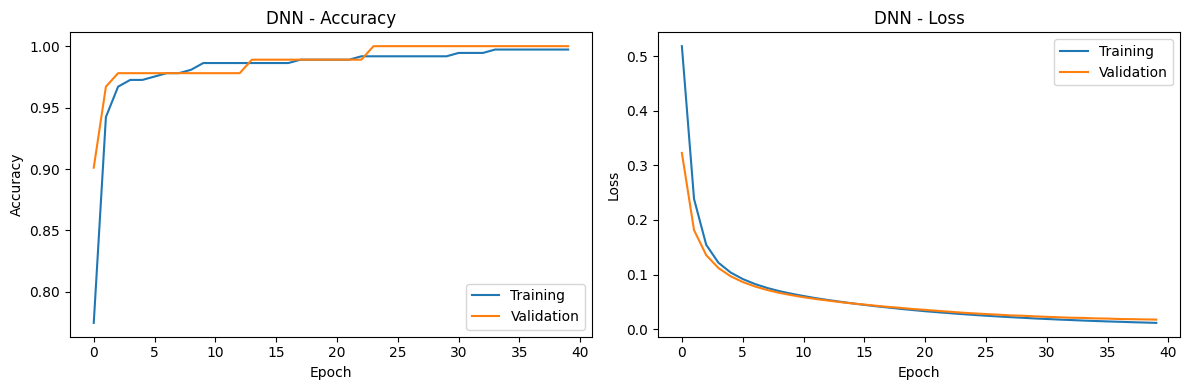

In [6]:
plot_history(history, "DNN")

Test loss: 0.0977
Test accuracy: 0.9649



Classification Report
              precision    recall  f1-score   support

   malignant       0.93      0.98      0.95        42
      benign       0.99      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.97      0.96       114
weighted avg       0.97      0.96      0.97       114



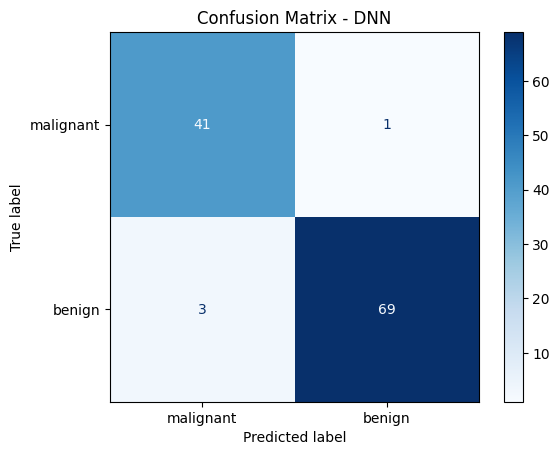

In [7]:
test_loss, test_accuracy = dnn.evaluate(X_test, y_test, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

y_prob = dnn.predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("\nClassification Report")
print(classification_report(y_test, y_pred, target_names=data.target_names))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=data.target_names).plot(
    cmap="Blues", values_format="d"
)
plt.title("Confusion Matrix - DNN")
plt.show()

The model reaches **96.5% test accuracy** (loss 0.0977). It detects 41 of 42 malignant cases (recall 0.98) and predicts 3 benign cases as malignant. Training and validation accuracy are both close to 100%, so there is some overfitting on this small dataset.

In [8]:
# Save the trained DNN
joblib.dump(dnn, "dnn_breast_cancer.joblib")
print("Saved dnn_breast_cancer.joblib")

Saved dnn_breast_cancer.joblib


### 7. Inference

In [9]:
# Load the saved model and predict five test samples
dnn_loaded = joblib.load("dnn_breast_cancer.joblib")

sample_X = X_test[:5]
sample_y = y_test[:5]
probabilities = dnn_loaded.predict(sample_X, verbose=0).ravel()
predictions = (probabilities >= 0.5).astype(int)

for i in range(5):
    print(
        f"Sample {i + 1}: predicted={data.target_names[predictions[i]]}, "
        f"actual={data.target_names[sample_y[i]]}, "
        f"P(benign)={probabilities[i]:.3f}"
    )

Sample 1: predicted=malignant, actual=malignant, P(benign)=0.000
Sample 2: predicted=benign, actual=benign, P(benign)=1.000
Sample 3: predicted=malignant, actual=malignant, P(benign)=0.000
Sample 4: predicted=malignant, actual=benign, P(benign)=0.188
Sample 5: predicted=malignant, actual=malignant, P(benign)=0.000


### 8. Conclusion
The ANN is a good baseline for breast cancer classification, with high malignant recall. The main limitation is the small dataset.

## Part 2 - CNN: Clothing Image Classification

### 1. Problem Definition
Classify clothing images into 10 categories. This can support automatic tagging and inventory management in online stores.

### 2. Dataset Description and Source
Fashion-MNIST: 70,000 grayscale 28x28 images in 10 classes, with 60,000 training and 10,000 test images.

Source: [Fashion-MNIST](https://github.com/zalandoresearch/fashion-mnist)

Loaded with `keras.datasets.fashion_mnist.load_data()`.

### 3. Proposed Solution
Train a CNN with two convolution-pooling blocks. Evaluate with accuracy, per-class metrics and a confusion matrix.

### 4. Data Preprocessing
Scale pixel values to [0, 1] and add a channel dimension, giving input shape 28x28x1. Labels stay as integers for sparse categorical cross-entropy.

In [10]:
(X_train_cnn, y_train_cnn), (X_test_cnn, y_test_cnn) = fashion_mnist.load_data()

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print("Training images:", X_train_cnn.shape)
print("Test images:", X_test_cnn.shape)
print("Images per class in training set:", np.bincount(y_train_cnn))

X_train_cnn = X_train_cnn.astype("float32") / 255.0
X_test_cnn = X_test_cnn.astype("float32") / 255.0
X_train_cnn = X_train_cnn[..., np.newaxis]
X_test_cnn = X_test_cnn[..., np.newaxis]

print("Input shape:", X_train_cnn.shape[1:])

Training images: (60000, 28, 28)
Test images: (10000, 28, 28)
Images per class in training set: [6000 6000 6000 6000 6000 6000 6000 6000 6000 6000]


Input shape: (28, 28, 1)


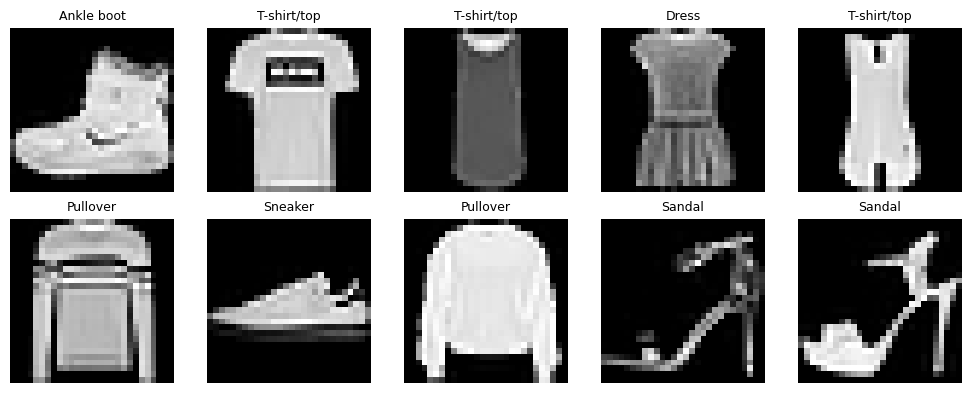

In [11]:
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train_cnn[i].squeeze(), cmap="gray")
    plt.title(class_names[y_train_cnn[i]], fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

### 5. Model Architecture
- Conv2D: 32 filters, 3x3, ReLU
- MaxPooling: 2x2
- Conv2D: 64 filters, 3x3, ReLU
- MaxPooling: 2x2
- Flatten
- Dense: 128 neurons, ReLU
- Dropout: 0.5
- Dense: 10 neurons, softmax

Adam optimizer, sparse categorical cross-entropy, 10 epochs, batch size 64.

In [12]:
cnn = keras.Sequential([
    keras.layers.Input(shape=(28, 28, 1)),
    keras.layers.Conv2D(32, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Conv2D(64, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(10, activation="softmax")
])

cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

### 6. Training Results and Evaluation

In [13]:
history_cnn = cnn.fit(
    X_train_cnn, y_train_cnn,
    validation_split=0.1,
    epochs=10,
    batch_size=64,
    verbose=2
)

Epoch 1/10


844/844 - 26s - 31ms/step - accuracy: 0.7866 - loss: 0.5928 - val_accuracy: 0.8432 - val_loss: 0.4089


Epoch 2/10


844/844 - 22s - 26ms/step - accuracy: 0.8556 - loss: 0.4000 - val_accuracy: 0.8763 - val_loss: 0.3309


Epoch 3/10


844/844 - 24s - 28ms/step - accuracy: 0.8727 - loss: 0.3479 - val_accuracy: 0.8907 - val_loss: 0.2953


... (10 outputs left out)

Epoch 9/10


844/844 - 27s - 32ms/step - accuracy: 0.9156 - loss: 0.2298 - val_accuracy: 0.9080 - val_loss: 0.2550


Epoch 10/10


844/844 - 20s - 24ms/step - accuracy: 0.9198 - loss: 0.2151 - val_accuracy: 0.9155 - val_loss: 0.2389


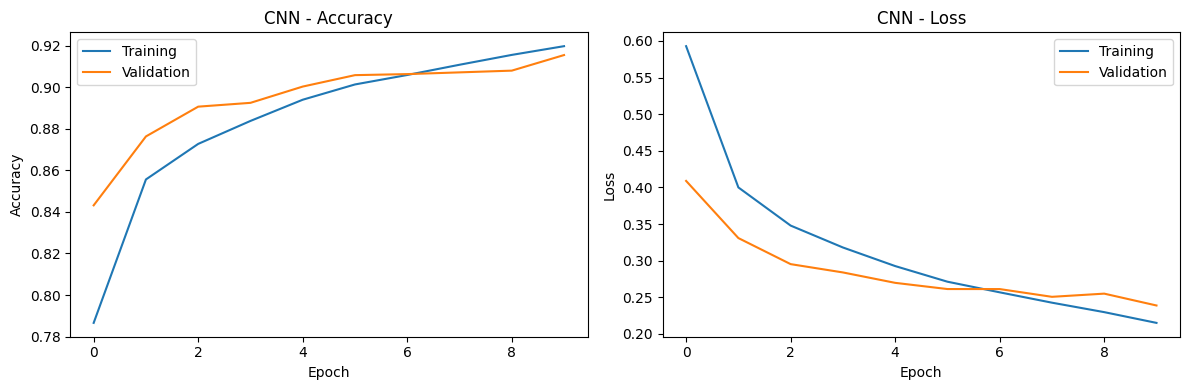

In [14]:
plot_history(history_cnn, "CNN")

Test loss: 0.2609
Test accuracy: 0.9080



Classification Report
              precision    recall  f1-score   support

 T-shirt/top       0.86      0.86      0.86      1000
     Trouser       1.00      0.98      0.99      1000
    Pullover       0.82      0.88      0.85      1000
       Dress       0.90      0.92      0.91      1000
        Coat       0.83      0.87      0.85      1000
      Sandal       0.97      0.99      0.98      1000
       Shirt       0.77      0.68      0.72      1000
     Sneaker       0.95      0.97      0.96      1000
         Bag       0.99      0.97      0.98      1000
  Ankle boot       0.98      0.95      0.96      1000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



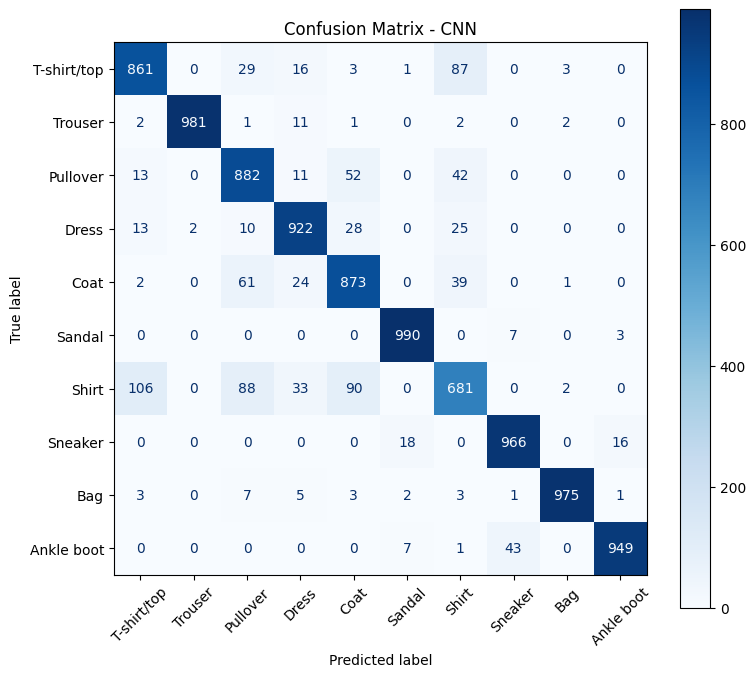

In [15]:
test_loss_cnn, test_accuracy_cnn = cnn.evaluate(X_test_cnn, y_test_cnn, verbose=0)
print(f"Test loss: {test_loss_cnn:.4f}")
print(f"Test accuracy: {test_accuracy_cnn:.4f}")

y_prob_cnn = cnn.predict(X_test_cnn, verbose=0)
y_pred_cnn = np.argmax(y_prob_cnn, axis=1)

print("\nClassification Report")
print(classification_report(y_test_cnn, y_pred_cnn, target_names=class_names))

cm_cnn = confusion_matrix(y_test_cnn, y_pred_cnn)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm_cnn, display_labels=class_names).plot(
    ax=ax, cmap="Blues", values_format="d", xticks_rotation=45
)
plt.title("Confusion Matrix - CNN")
plt.tight_layout()
plt.show()

The model reaches **90.8% test accuracy** (loss 0.2609). Trousers, bags, sandals and sneakers are classified well (F1 about 0.96-0.99). Shirts are the weakest class (recall 0.68), often confused with T-shirts, pullovers and coats.

In [16]:
# Save the trained CNN
joblib.dump(cnn, "cnn_fashion_mnist.joblib")
print("Saved cnn_fashion_mnist.joblib")

Saved cnn_fashion_mnist.joblib


### 7. Inference

Sample 1: predicted=Ankle boot, actual=Ankle boot, confidence=1.000
Sample 2: predicted=Pullover, actual=Pullover, confidence=1.000
Sample 3: predicted=Trouser, actual=Trouser, confidence=1.000
Sample 4: predicted=Trouser, actual=Trouser, confidence=1.000
Sample 5: predicted=Shirt, actual=Shirt, confidence=0.945


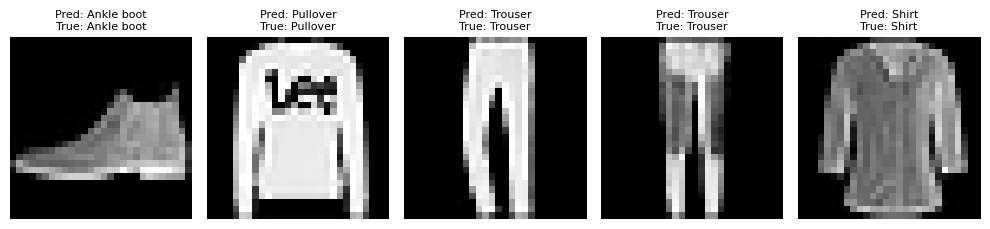

In [17]:
# Load the saved model and predict five test images
cnn_loaded = joblib.load("cnn_fashion_mnist.joblib")

sample_X = X_test_cnn[:5]
sample_y = y_test_cnn[:5]
probabilities = cnn_loaded.predict(sample_X, verbose=0)
predictions = np.argmax(probabilities, axis=1)

for i in range(5):
    confidence = probabilities[i][predictions[i]]
    print(
        f"Sample {i + 1}: predicted={class_names[predictions[i]]}, "
        f"actual={class_names[sample_y[i]]}, confidence={confidence:.3f}"
    )

plt.figure(figsize=(10, 3))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(sample_X[i].squeeze(), cmap="gray")
    plt.title(f"Pred: {class_names[predictions[i]]}\nTrue: {class_names[sample_y[i]]}", fontsize=8)
    plt.axis("off")
plt.tight_layout()
plt.show()

### 8. Conclusion
The CNN works well for clear clothing categories. The main limitation is the low image resolution, which makes similar upper-body classes hard to separate.

## Overall Conclusion
The DNN reached 96.5% accuracy on tabular data, and the CNN reached 90.8% on images. Fully connected layers were enough for the numerical data, while convolution layers were better for images.